# Prelude

In [1]:
%cd /home/mfixman/TP/MyPyCop

/home/mfixman/Dropbox/continuous/TP/MyPyCop


In [2]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [3]:
seaborn.set()

# Getting Data

In [4]:
%pwd

'/home/mfixman/Dropbox/continuous/TP/MyPyCop'

In [5]:
data = pandas.concat(
    [
        pandas.read_csv(
            'results/SATSolveCoP.csv',
        ),
    ],
    ignore_index = True,
).drop_duplicates(['problem', 'strategy'])

In [6]:
strategies = data.strategy.unique()
strategies

array(['SATSolve', 'SATSolveLiteral', 'SATCoPRust'], dtype=object)

In [7]:
# problems = data.xs(level = 'strategy', key = 'SATSolveGuided').index.str[:3].unique()
# data = data[data.index.get_level_values('problem').str[:3].isin(problems)]
# problems

In [8]:
# data = data.groupby(level = 'problem').filter(lambda x: x.solved.count() == len(strategies))

In [9]:
data.problem.str[:3].unique()

array(['AGT', 'ALG', 'ANA', 'BOO', 'CAT', 'COL', 'COM', 'CSR', 'FLD',
       'GEO', 'GRA', 'GRP', 'HEN', 'HWV', 'KLE', 'KRS', 'LAT', 'LCL',
       'LDA', 'MED', 'MGT', 'NLP', 'NUM', 'PLA', 'PRO', 'PUZ', 'REL',
       'RNG', 'SCT', 'SET', 'SEU', 'SEV', 'SWB', 'SWC', 'SWV', 'SWW',
       'SYN', 'SYO', 'TOP', 'HAL', 'MSC', 'ROB', 'BIO', 'NUN', 'HWC',
       'PHI'], dtype=object)

# Analysing

In [10]:
control = ['FirstAction', 'LeanCopCut']

In [11]:
data[data.solved]

,problem,strategy,status,solved,steps,time_ms,info,error
0,AGT002+2.p,SATSolve,solved,True,0.0,0.0,Theorem (SAT),NaN
1,AGT002+2.p,SATSolveLiteral,solved,True,0.0,0.0,Theorem (SAT),NaN
2,AGT002+2.p,SATCoPRust,solved,True,0.0,0.0,Theorem (SAT),NaN
19,ALG227+1.p,SATSolveLiteral,solved,True,88375.0,80792.0,Theorem (SAT); score=1.0; literal=choices:5041...,NaN
75,CSR062+1.p,SATSolve,solved,True,2218.0,929.0,Theorem (SAT),NaN
...,...,...,...,...,...,...,...,...
4050,SYN729-1.p,SATSolve,solved,True,227.0,110.0,Theorem (SAT),NaN
4051,SYN729-1.p,SATSolveLiteral,solved,True,113.0,31.0,"Theorem (SAT); literal=choices:64,forward:189,...",NaN
4065,SYN969+1.p,SATSolve,solved,True,13.0,2.0,Theorem (SAT),NaN
4066,SYN969+1.p,SATSolveLiteral,solved,True,13.0,2.0,"Theorem (SAT); literal=choices:8,forward:14,un...",NaN


In [12]:
data[data.solved].groupby('strategy').size()

strategy
SATCoPRust          69
SATSolve           151
SATSolveLiteral    219
dtype: int64

# Results

<Axes: xlabel='strategy'>

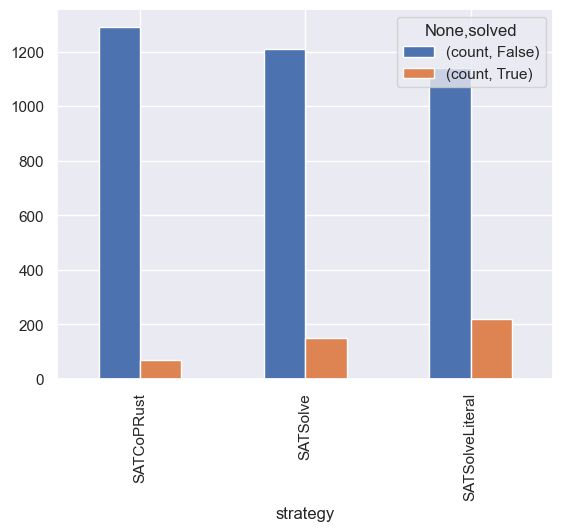

In [13]:
data.groupby('strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()

In [14]:
merged = pandas.merge(
    data,
    data,
    left_on = 'problem',
    right_on = 'problem',
    suffixes = ('_left', '_right'),
)

In [20]:
pandas.crosstab(merged.strategy_left, merged.strategy_right)

strategy_right,SATCoPRust,SATSolve,SATSolveLiteral
strategy_left,,,
SATCoPRust,1360,1360,1360
SATSolve,1360,1360,1360
SATSolveLiteral,1360,1360,1360


In [22]:
results

Winner,SATSolve,SATSolveLiteral
Loser,,
SATCoPRust,82,150
SATSolve,0,68


In [25]:

    merged [~merged.solved_left & merged.solved_right] [['strategy_left', 'strategy_right']] .value_counts()

strategy_left  strategy_right 
SATCoPRust     SATSolveLiteral    150
               SATSolve            82
SATSolve       SATSolveLiteral     68
Name: count, dtype: int64

In [30]:
results.reindex(index = data.strategy.unique(), columns = data.strategy.unique())

Winner,SATSolve,SATSolveLiteral,SATCoPRust
Loser,,,
SATSolve,0.0,68.0,NaN
SATSolveLiteral,NaN,NaN,NaN
SATCoPRust,82.0,150.0,NaN


In [35]:
plot

Winner,SATSolve,SATSolveLiteral,SATCoPRust
Loser,,,
SATSolve,0,68,0
SATSolveLiteral,0,0,0
SATCoPRust,82,150,0


In [40]:
results.where(~numpy.eye(results.index.size, dtype = bool))

Winner,SATSolve,SATSolveLiteral,SATCoPRust
Loser,,,
SATSolve,NaN,68.0,0.0
SATSolveLiteral,0.0,NaN,0.0
SATCoPRust,82.0,150.0,NaN


Text(0.5, 1.0, 'Winners and losers of different SAT policies. Total of 1,360 problems.')

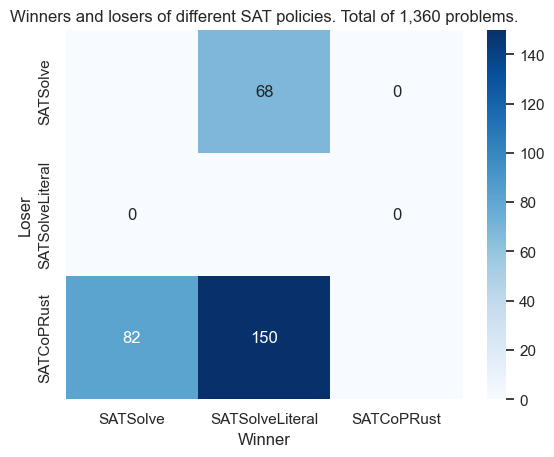

In [50]:
results = (
    merged
    [~merged.solved_left & merged.solved_right]
    [['strategy_left', 'strategy_right']]
    .value_counts()
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'Loser', columns = 'Winner')
    .reindex(index = merged.strategy_left.unique(), columns = merged.strategy_left.unique(), fill_value = 0)
)

cols = results.columns[results.columns.str.startswith('SAT') & ~results.columns.str.endswith('Literal')]
cols = results.columns
plot = (
    results.
    loc[cols, cols].
    rename_axis(index = 'Loser', columns = 'Winner').
    rename(index = lambda x: x.removeprefix('SATSolveGuided') if x != 'SATSolveGuided' else 'Guided').
    rename(columns = lambda x: x.removeprefix('SATSolveGuided') if x != 'SATSolveGuided' else 'Guided')
)

seaborn.heatmap(
    plot,
    annot = plot.astype(str).where(~numpy.eye(results.index.size, dtype = bool), other = ''),
    fmt = 's',
    cmap = 'Blues',
)
pyplot.title(f'Winners and losers of different SAT policies. Total of {merged.problem.nunique():,d} problems.')
# pyplot.savefig('figures/sat_policies_plot.png', bbox_inches = 'tight')

In [ ]:
subset = merged[merged.problem.str.contains(r'\+')]

results = (
    subset
    [~subset.solved_left & subset.solved_right]
    [['strategy_left', 'strategy_right']]
    .value_counts()
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'Loser', columns = 'Winner')
)

cols = results.columns
plot = (
    results.
    loc[cols, cols].
    rename_axis(index = 'Loser', columns = 'Winner').
    rename(index = lambda x: x.removeprefix('SATSolveGuided') if x != 'SATSolveGuided' else 'Guided').
    rename(columns = lambda x: x.removeprefix('SATSolveGuided') if x != 'SATSolveGuided' else 'Guided')
)

seaborn.heatmap(
    plot,
    annot = plot.map(lambda x: f'{x:d}' if x != 0 else ''),
    fmt = 's',
    cmap = 'Blues',
)
pyplot.title(f'Winners and losers of different SAT policies. Total of {subset.problem.nunique():,d} problems.')
# pyplot.savefig('figures/sat_policies_plot.png', bbox_inches = 'tight')

# Analysis

## Hard Problems

In [ ]:
literal = data[data.strategy == 'SATSolveLiteral'].loc[lambda x: x.solved]

In [ ]:
literal[literal.problem.str.startswith('SYN')].sort_values('steps', ascending = False).head(40)